# Mixture geometry, latent classes and missing data
Compare the supplied coordinate datasets with independent held-out selection.
Read [the full derivations](../docs/10_course_projects.md) and [measured results](../docs/project_results.md).
The synthetic coordinates are not clinical image data.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
m = evidence('course_mixtures')
rows = pd.DataFrame(m['rows'])
rows.groupby(['dataset','model'])[['test_ari','test_nll']].agg(['mean','std'])

test_ari            test_nll          
                             mean       std      mean       std
dataset model                                                  
1       custom_em_k3     0.910265  0.013628  3.787967  0.029248
        kmeans           0.951508  0.063501       NaN       NaN
        selected_gmm     0.910265  0.013628  3.788563  0.028533
        sklearn_em_k3    0.910265  0.013628  3.788564  0.028533
        variational_gmm  0.910265  0.013628  3.813301  0.029543
2       custom_em_k3     0.019287  0.025360  2.826469  0.020404
        kmeans           0.014862  0.020770       NaN       NaN
        selected_gmm     0.014866  0.028502  2.826591  0.019258
        sklearn_em_k3    0.016872  0.027336  2.826725  0.020891
        variational_gmm  0.000956  0.000877  2.843004  0.038443

## Geometry and identifiability
The means separate in Image 1 and nearly coincide in Image 2. Covariance differences
can help model density without making the generating label predictable. Labels
below are used only to inspect the stated contiguous groups.

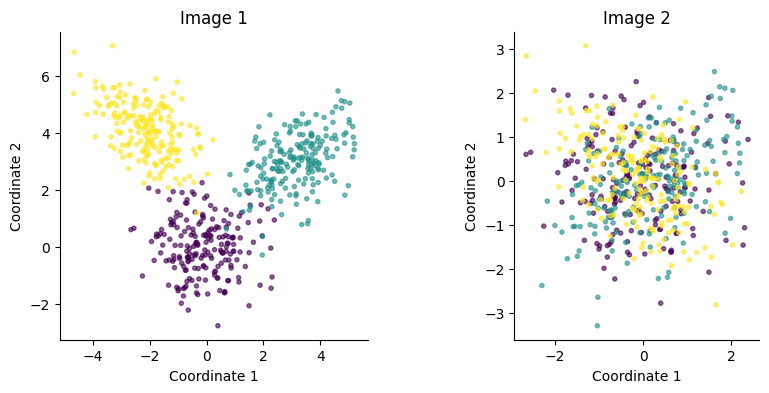

In [3]:
points = np.load(root / 'assets/source_data/assignment_points.npz')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i, ax in enumerate(axes, 1):
    x = points[f'image{i}']
    ax.scatter(*x.T, c=np.repeat(np.arange(3), 200), s=9, alpha=.6, cmap='viridis')
    ax.set(title=f'Image {i}', xlabel='Coordinate 1', ylabel='Coordinate 2')
    ax.set_aspect('equal')
plt.show()

In [4]:
pd.DataFrame(m['imputation']).groupby('dataset')[['conditional_gmm_rmse','mean_imputation_rmse']].mean()

,conditional_gmm_rmse,mean_imputation_rmse
dataset,,
1,1.350978,1.989554
2,0.959395,0.971856


## Categorical EM with missing features
The posterior of a completely missing row equals the prior component weights.
Smoothed updates count only observed entries. Inspect both model recovery and
imputation rather than treating high training likelihood as sufficient evidence.

In [5]:
from learning_lab.categorical import CategoricalMixtureEM
x = np.array([[0,0],[0,1],[1,1],[1,-1],[-1,0]])
model = CategoricalMixtureEM(2,2,seed=3).fit(x)
np.testing.assert_allclose(model.predict_proba([[-1,-1]]),model.weights_[None])
pd.Series({key:value for key,value in m['categorical_mixture'].items() if key not in ['history','protocol','learned_weights']})

test_nll_observed                                                        3.383299
latent_test_ari                                                           0.99279
missing_accuracy                                                         0.901416
majority_missing_accuracy                                                0.567745
majority_protocol               Per-feature observed-value modes from masked f...
majority_modes                                           [0, 1, 2, 0, 1, 2, 0, 1]
majority_observed_fit_counts     [2260, 2268, 2249, 2233, 2246, 2263, 2276, 2250]
dtype: object

## Worked answer
An unconstrained mixture of one categorical variable identifies only its weighted
marginal, not each latent component. Multiple conditionally independent features
supply observable dependence. The executed experiment uses eight features and 25%
missing entries; its success is a controlled result, not a universal imputation guarantee.